### Импорт библиотек

In [98]:
import collections
import math
import matplotlib.pyplot as plt

### Функция предварительной обработки текста

In [99]:
def preprocess_text(text):
    allowed_chars = set("абвгдежзийклмнопрстуфхцчшщъыьэюя")
    normalized = text.lower().replace("ё", "е")
    return "".join([char for char in normalized if char in allowed_chars])

### Функция расчета энтропии k-грамм

In [100]:
def calculate_k_gram_entropy(text, k):
    if len(text) < k:
        return 0.0
    
    k_grams = [text[i:i+k] for i in range(len(text) - k + 1)]
    total_grams = len(k_grams)
    counts = collections.Counter(k_grams)
    entropy = 0.0

    for count in counts.values():
        probability = count / total_grams
        entropy -= probability * math.log2(probability)
    return entropy / k

### Основной блок выполнения и построения графика

In [101]:
sample_text = """
Выхожу один я на дорогу; Сквозь туман кремнистый путь блестит;
Ночь тиха. Пустыня внемлет богу, И звезда с звездою говорит. В небесах
торжественно и чудно! Спит земля в сияньи голубом... Что же мне так
больно и так трудно? Жду ль чего? Жалею ли о чём?
"""

In [102]:
cleaned_text = preprocess_text(sample_text)

In [103]:
cleaned_text

'выхожуодинянадорогусквозьтуманкремнистыйпутьблеститночьтихапустынявнемлетбогуизвездасзвездоюговоритвнебесахторжественноичудноспитземлявсияньиголубомчтожемнетакбольноитактруднождульчегожалеюлиочем'

In [104]:
k_values = list(range(1, 6))

entropy_values = [calculate_k_gram_entropy(cleaned_text, k) for k in k_values]

for k, h in zip(k_values, entropy_values):
    print(f"k = {k}: H_k(T)/k = {h:.5f}")

k = 1: H_k(T)/k = 4.42387
k = 2: H_k(T)/k = 3.43268
k = 3: H_k(T)/k = 2.48591
k = 4: H_k(T)/k = 1.88843
k = 5: H_k(T)/k = 1.51339


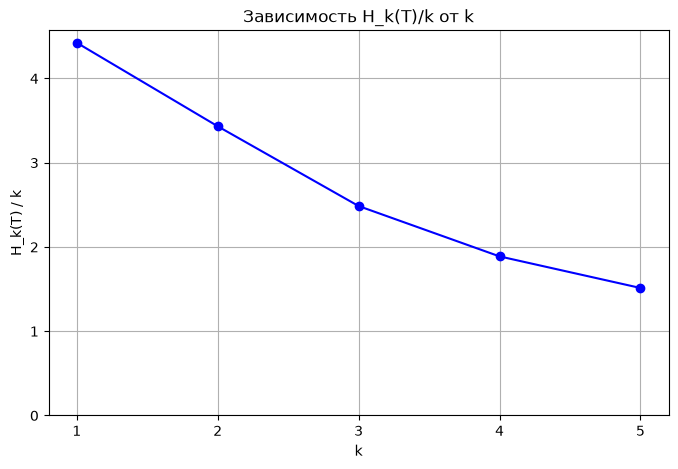

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, entropy_values, marker='o', linestyle='-', color='b')
plt.title("Зависимость H_k(T)/k от k")
plt.xlabel("k")
plt.ylabel("H_k(T) / k")
plt.grid(True)
plt.xticks(k_values)
plt.ylim(bottom=0)
plt.show()